<a href="https://colab.research.google.com/github/Mohamed-Eco/EcoForecast-Analysis/blob/Master/EcoForecast_Analysis_Clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EcoForecast: Macro-Financial Analysis (2015-2025)
**Author:** Mohamed-Eco
**Objective:** To analyze the impact of US monetary policy (Fed Rate & DXY) on the GDP growth of five North African countries using Panel Data Analysis.


## 1. Setup & Data Loading
Installing necessary libraries and importing the cleaned dataset.





In [9]:
# Install required packages
!pip install linearmodels -q

import pandas as pd
import numpy as np
import statsmodels.api as sm
from linearmodels.panel import PanelOLS
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
# 1. Load the dataset from the SECOND sheet (which contains the real data)
# We use sheet_name=1 to read the second sheet
df = pd.read_excel('Master_Micro_DATA_Finale.xlsx', sheet_name=1)

# 2. Clean column names: strip spaces and convert to lowercase
df.columns = df.columns.str.strip().str.lower()

# 3. Format year and set MultiIndex (Country, Year)
# Since 'year' and 'country' are now present and lowercase, this will work perfectly
df['year'] = pd.to_datetime(df['year'].astype(str), format='%Y')
df = df.set_index(['country', 'year'])

# 4. Display first rows to verify
print("✅ Data loaded successfully from the correct sheet. First 5 rows:")
print(df[['gdp_growth_pct', 'us_dollar_index', 'fed_rate_pct', 'inflation_rate_pct']].head())

✅ Data loaded successfully from the correct sheet. First 5 rows:
                    gdp_growth_pct  us_dollar_index  fed_rate_pct  \
country year                                                        
Algeria 2015-01-01         4.15864             98.6          0.30   
        2016-01-01         2.79319             96.7          3.90   
        2017-01-01         2.19161             96.6          1.00   
        2018-01-01         3.18160             93.6          1.83   
        2019-01-01         2.04430             96.1          2.16   

                    inflation_rate_pct  
country year                            
Algeria 2015-01-01             4.78445  
        2016-01-01             6.39769  
        2017-01-01             5.59112  
        2018-01-01             4.26999  
        2019-01-01             1.95177  


## 2. Stationarity Check (ADF Test)
Before running the regression, we must ensure our time-series data is stationary to avoid spurious regression. We use the Augmented Dickey-Fuller (ADF) test.

In [12]:
# 1. Test GDP Growth
print("--- ADF Test: gdp_growth_pct ---")
res_gdp = adfuller(df['gdp_growth_pct'].dropna())
print(f"P-value: {res_gdp[1]:.4f}")

# 2. Test Fed Rate
print("\n--- ADF Test: fed_rate_pct ---")
res_fed = adfuller(df['fed_rate_pct'].dropna())
print(f"P-value: {res_fed[1]:.4f}")

# 3. Test Inflation Rate
print("\n--- ADF Test: inflation_rate_pct ---")
res_inf = adfuller(df['inflation_rate_pct'].dropna())
print(f"P-value: {res_inf[1]:.4f}")

--- ADF Test: gdp_growth_pct ---
P-value: 0.0000

--- ADF Test: fed_rate_pct ---
P-value: 0.0000

--- ADF Test: inflation_rate_pct ---
P-value: 0.4148


/tmp/ipykernel_598/1858925785.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res_gdp = adfuller(df['gdp_growth_pct'].dropna())
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/stattools/_stattools.py:149: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  results[lag] = mod_instance.fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/stattools/_stattools.py:149: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  results[lag] = mod_instance.fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/stattools/_stattools.py:432: Singular

## 3. Data Transformation & PanelOLS Estimation
Variables with high P-values in the ADF test are non-stationary. We calculate the first differences to make the data stationary. Then, we run a PanelOLS model with Entity Effects (Fixed Effects).

In [13]:
# 1. Calculate First Differences to achieve stationarity
df['d_fed_rate'] = df.groupby('country')['fed_rate_pct'].diff()
df['d_inflation'] = df.groupby('country')['inflation_rate_pct'].diff()
df['d_dxy'] = df.groupby('country')['us_dollar_index'].diff()

# 2. Prepare dependent and independent variables
y = df['gdp_growth_pct']
X = df[['d_fed_rate', 'd_inflation', 'd_dxy']]
X = sm.add_constant(X) # Add constant

# 3. Clean data (drop NaN values created by differencing)
valid_data = pd.concat([y, X], axis=1).dropna()
y_final = valid_data.iloc[:, 0]
X_final = valid_data.iloc[:, 1:]

# 4. Run PanelOLS (Fixed Effects)
model_final = PanelOLS(y_final, X_final, entity_effects=True).fit()

print("\n--- Final EcoForecast Model Results ---")
print(model_final.summary)


--- Final EcoForecast Model Results ---
                          PanelOLS Estimation Summary                           
Dep. Variable:         gdp_growth_pct   R-squared:                        0.0844
Estimator:                   PanelOLS   R-squared (Between):             -0.0008
No. Observations:                  50   R-squared (Within):               0.0844
Date:                Sat, Oct 31 2026   R-squared (Overall):              0.0824
Time:                        20:20:47   Log-likelihood                   -174.63
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      1.2912
Entities:                           5   P-value                           0.2899
Avg Obs:                      10.0000   Distribution:                    F(3,42)
Min Obs:                      10.0000                                           
Max Obs:                      10.0000   F-statistic (robust):       

## 4. Data Visualization
Visualizing the economic trajectory of North African countries and the inverse relationship between the US Dollar Index (DXY) and GDP Growth.

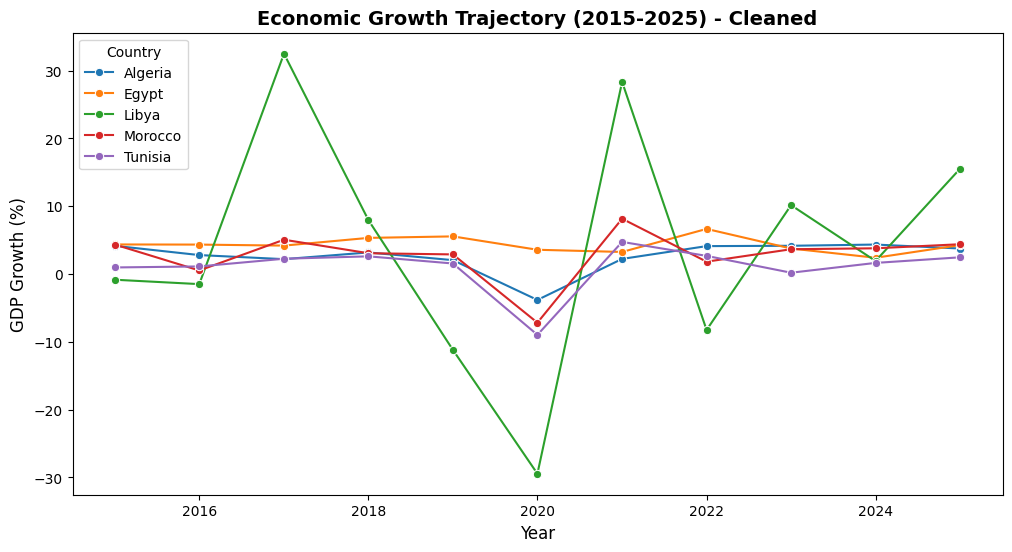

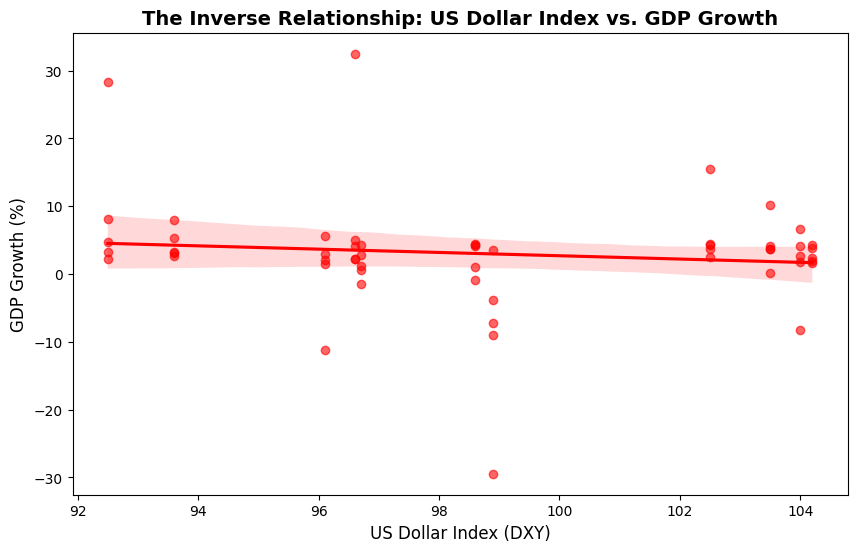

In [14]:
# Reset index for plotting
df_plot = df.reset_index()

# Plot 1: Economic Growth Trajectory
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_plot, x='year', y='gdp_growth_pct', hue='country', marker='o')
plt.title('Economic Growth Trajectory (2015-2025) - Cleaned', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('GDP Growth (%)', fontsize=12)
plt.legend(title='Country')
plt.savefig('EcoForecast_Growth_Chart.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot 2: The Inverse Relationship (DXY vs GDP)
plt.figure(figsize=(10, 6))
sns.regplot(data=df_plot, x='us_dollar_index', y='gdp_growth_pct', color='red', scatter_kws={'alpha':0.6})
plt.title('The Inverse Relationship: US Dollar Index vs. GDP Growth', fontsize=14, fontweight='bold')
plt.xlabel('US Dollar Index (DXY)', fontsize=12)
plt.ylabel('GDP Growth (%)', fontsize=12)
plt.savefig('EcoForecast_Correlation_Chart.png', dpi=300, bbox_inches='tight')
plt.show()